In [2]:
import os
import numpy as np
import pandas as pd

# I. Load and familiarize with input data

Test on cell line A-253

In [4]:
# Read input files
mtx_dir = f"input/cellsnp/A-253"

dist_dir = f"output/distances for all exons/A-253"
dist_mtx = pd.read_csv(f"{dist_dir}/A-253_SomaticMutations_distance.csv", sep="\t", header=0, names=["chr", "pos", "dist"])

aggregated_mtx = pd.read_csv(f"{mtx_dir}/cellSNP.base.vcf.gz", 
                             compression='gzip', 
                             sep="\t", 
                             comment="#", 
                             header=None, 
                             names=["chr", "pos", "id", "ref", "alt", "qual", "filter", "info"
])

In [5]:
print("General info on distance matrix:")
dist_mtx.info()
print("---------------------------")
print("First entries of distance matrix:")
display(dist_mtx.head())

General info on distance matrix:
<class 'pandas.DataFrame'>
RangeIndex: 199 entries, 0 to 198
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   chr     199 non-null    str    
 1   pos     199 non-null    int64  
 2   dist    195 non-null    float64
dtypes: float64(1), int64(1), str(1)
memory usage: 4.8 KB
---------------------------
First entries of distance matrix:


,chr,pos,dist
0,chr1,7732517,5253.000000
1,chr1,35381360,5610.000000
2,chr1,93183407,2188.285714
3,chr1,103543381,1514.800000
4,chr1,110018571,1604.000000


In [6]:
print("General info on callability matrix:")
aggregated_mtx.info()
print("---------------------------")
print("First entries of callability matrix:")
display(aggregated_mtx.head())

General info on callability matrix:
<class 'pandas.DataFrame'>
RangeIndex: 99 entries, 0 to 98
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   chr     99 non-null     str  
 1   pos     99 non-null     int64
 2   id      99 non-null     str  
 3   ref     99 non-null     str  
 4   alt     99 non-null     str  
 5   qual    99 non-null     str  
 6   filter  99 non-null     str  
 7   info    99 non-null     str  
dtypes: int64(1), str(7)
memory usage: 6.3 KB
---------------------------
First entries of callability matrix:


,chr,pos,id,ref,alt,qual,filter,info
0,chr1,93183407,.,G,T,.,PASS,AD=0;DP=1;OTH=0
1,chr1,103543381,.,A,G,.,PASS,AD=1;DP=1;OTH=0
2,chr1,110018571,.,A,G,.,PASS,AD=0;DP=1;OTH=0
3,chr1,151017873,.,C,G,.,PASS,AD=0;DP=1;OTH=0
4,chr1,151424987,.,G,A,.,PASS,AD=0;DP=3;OTH=0


In [7]:
# Split "info" column into 3 separate one to make further analysis easier
keys = ["AD", "DP", "OTH"]
aggregated_mtx[["AD", "DP", "OTH"]] = aggregated_mtx["info"].str.split(";", expand=True)
# Reformat columns AD and DP, remove chars "DP="
# Example: DP=1 -> 1
aggregated_mtx[["Drop_1","DP"]] = aggregated_mtx["DP"].str.split("=", expand=True)
aggregated_mtx[["Drop_2","AD"]] = aggregated_mtx["AD"].str.split("=", expand=True)
aggregated_mtx = aggregated_mtx.drop(["info", "Drop_1", "Drop_2", "OTH"], axis="columns")
# Change values of columns AD and DP to numeric
aggregated_mtx["DP"] = pd.to_numeric(aggregated_mtx["DP"])
aggregated_mtx["AD"] = pd.to_numeric(aggregated_mtx["AD"])

In [8]:
aggregated_mtx.head()

,chr,pos,id,ref,alt,qual,filter,AD,DP
0,chr1,93183407,.,G,T,.,PASS,0,1
1,chr1,103543381,.,A,G,.,PASS,1,1
2,chr1,110018571,.,A,G,.,PASS,0,1
3,chr1,151017873,.,C,G,.,PASS,0,1
4,chr1,151424987,.,G,A,.,PASS,0,3


# II. Filter variant table by thresholds k

Use disjoint filter k:

1. DP={1,5}
2. DP={6,10}
3. DP={11,15}
4. DP={16,20}

In [9]:
thresholds_1 = np.arange(1,6)
thresholds_2 = np.arange(6,11)
thresholds_3 = np.arange(11,16)
thresholds_4 = 16

In [10]:
aggregated_mtx_1 = aggregated_mtx[aggregated_mtx["DP"].isin(thresholds_1)].copy()
aggregated_mtx_2 = aggregated_mtx[aggregated_mtx["DP"].isin(thresholds_2)].copy()
aggregated_mtx_3 = aggregated_mtx[aggregated_mtx["DP"].isin(thresholds_3)].copy()
aggregated_mtx_4 = aggregated_mtx[aggregated_mtx["DP"] >= thresholds_4].copy()

In [11]:
aggregated_mtx_1 = aggregated_mtx_1.merge(dist_mtx, on=["chr", "pos"])
aggregated_mtx_2 = aggregated_mtx_2.merge(dist_mtx, on=["chr", "pos"])
aggregated_mtx_3 = aggregated_mtx_3.merge(dist_mtx, on=["chr", "pos"])
aggregated_mtx_4 = aggregated_mtx_4.merge(dist_mtx, on=["chr", "pos"])

In [12]:
aggregated_mtx_1.info()

<class 'pandas.DataFrame'>
RangeIndex: 63 entries, 0 to 62
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   chr     63 non-null     str    
 1   pos     63 non-null     int64  
 2   id      63 non-null     str    
 3   ref     63 non-null     str    
 4   alt     63 non-null     str    
 5   qual    63 non-null     str    
 6   filter  63 non-null     str    
 7   AD      63 non-null     int64  
 8   DP      63 non-null     int64  
 9   dist    63 non-null     float64
dtypes: float64(1), int64(3), str(6)
memory usage: 5.1 KB


# III. Plot data

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt

In [15]:
distances_1 = aggregated_mtx_1["dist"].tolist()
distances_2 = aggregated_mtx_2["dist"].tolist()
distances_3 = aggregated_mtx_3["dist"].tolist()
distances_4 = aggregated_mtx_4["dist"].tolist()

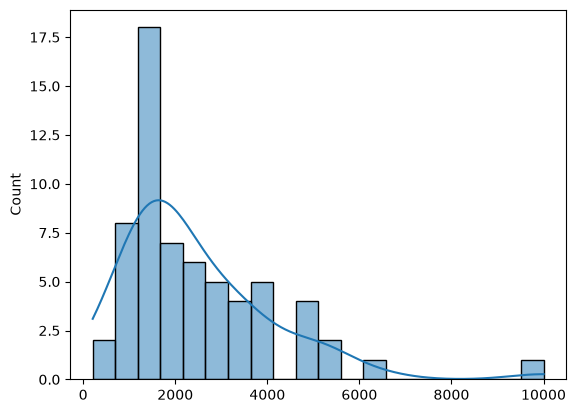

In [16]:
sns.histplot(distances_1,
             bins=20,
             kde=True)
plt.show()

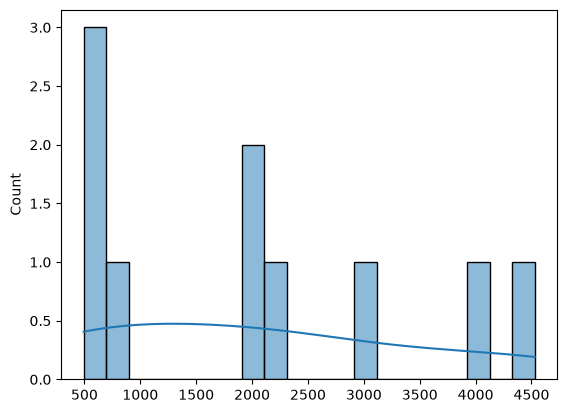

In [17]:
sns.histplot(distances_2,
             bins=20,
             kde=True)
plt.show()

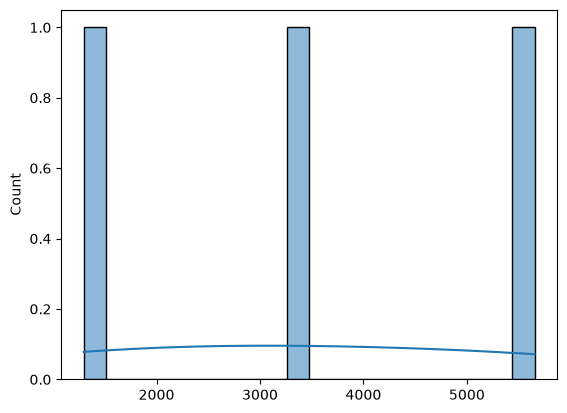

In [18]:
sns.histplot(distances_3,
             bins=20,
             kde=True)
plt.show()

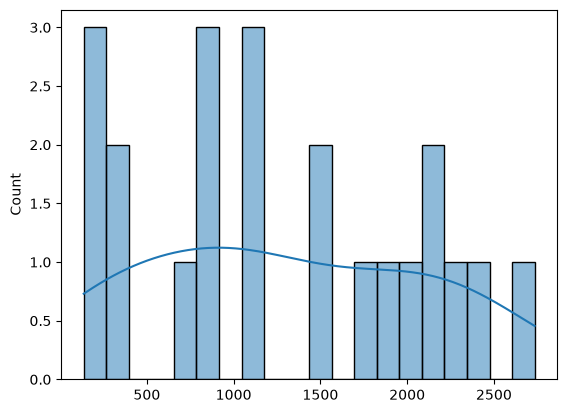

In [19]:
sns.histplot(distances_4,
             bins=20,
             kde=True)
plt.show()

Too little data for analysis?

## Test on cell lines HCT-15 and HCT-116

In [21]:
# Read input files
mtx_dir = f"input/cellsnp/HCT-15"

dist_dir = f"output/distances for all exons/HCT-15"
dist_mtx = pd.read_csv(f"{dist_dir}/HCT-15_SomaticMutations_distance.csv", sep="\t", header=0, names=["chr", "pos", "dist"])

aggregated_mtx = pd.read_csv(f"{mtx_dir}/cellSNP.base.vcf.gz", 
                             compression='gzip', 
                             sep="\t", 
                             comment="#", 
                             header=None, 
                             names=["chr", "pos", "id", "ref", "alt", "qual", "filter", "info"
])

In [22]:
print("General info on distance matrix:")
dist_mtx.info()
print("---------------------------")
print("First entries of distance matrix:")
display(dist_mtx.head())

General info on distance matrix:
<class 'pandas.DataFrame'>
RangeIndex: 4800 entries, 0 to 4799
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   chr     4800 non-null   str    
 1   pos     4800 non-null   int64  
 2   dist    4641 non-null   float64
dtypes: float64(1), int64(1), str(1)
memory usage: 112.6 KB
---------------------------
First entries of distance matrix:


,chr,pos,dist
0,chr1,970887,1641.750000
1,chr1,1185014,818.666667
2,chr1,1197179,351.000000
3,chr1,1217586,577.857143
4,chr1,1246578,891.000000


In [23]:
print("General info on callability matrix:")
aggregated_mtx.info()
print("---------------------------")
print("First entries of callability matrix:")
display(aggregated_mtx.head())

General info on callability matrix:
<class 'pandas.DataFrame'>
RangeIndex: 2688 entries, 0 to 2687
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   chr     2688 non-null   str  
 1   pos     2688 non-null   int64
 2   id      2688 non-null   str  
 3   ref     2688 non-null   str  
 4   alt     2688 non-null   str  
 5   qual    2688 non-null   str  
 6   filter  2688 non-null   str  
 7   info    2688 non-null   str  
dtypes: int64(1), str(7)
memory usage: 168.1 KB
---------------------------
First entries of callability matrix:


,chr,pos,id,ref,alt,qual,filter,info
0,chr1,1217586,.,C,T,.,PASS,AD=1;DP=6;OTH=0
1,chr1,1299857,.,G,A,.,PASS,AD=0;DP=2;OTH=0
2,chr1,1312656,.,G,C,.,PASS,AD=2;DP=2;OTH=0
3,chr1,1374038,.,G,A,.,PASS,AD=2176;DP=4365;OTH=8
4,chr1,1402091,.,A,G,.,PASS,AD=2343;DP=4732;OTH=5


In [24]:
# Split "info" column into 3 separate one to make further analysis easier
keys = ["AD", "DP", "OTH"]
aggregated_mtx[["AD", "DP", "OTH"]] = aggregated_mtx["info"].str.split(";", expand=True)
# Reformat columns AD and DP, remove chars "DP="
# Example: DP=1 -> 1
aggregated_mtx[["Drop_1","DP"]] = aggregated_mtx["DP"].str.split("=", expand=True)
aggregated_mtx[["Drop_2","AD"]] = aggregated_mtx["AD"].str.split("=", expand=True)
aggregated_mtx = aggregated_mtx.drop(["info", "Drop_1", "Drop_2", "OTH"], axis="columns")
# Change values of columns AD and DP to numeric
aggregated_mtx["DP"] = pd.to_numeric(aggregated_mtx["DP"])
aggregated_mtx["AD"] = pd.to_numeric(aggregated_mtx["AD"])

In [25]:
thresholds_1 = np.arange(1,6)
thresholds_2 = np.arange(6,11)
thresholds_3 = np.arange(11,16)
thresholds_4 = 16

aggregated_mtx_1 = aggregated_mtx[aggregated_mtx["AD"].isin(thresholds_1)].copy()
aggregated_mtx_2 = aggregated_mtx[aggregated_mtx["AD"].isin(thresholds_2)].copy()
aggregated_mtx_3 = aggregated_mtx[aggregated_mtx["AD"].isin(thresholds_3)].copy()
aggregated_mtx_4 = aggregated_mtx[aggregated_mtx["AD"] >= thresholds_4].copy()

display(aggregated_mtx_1.info())
display(aggregated_mtx_2.info())
display(aggregated_mtx_3.info())
display(aggregated_mtx_4.info())


aggregated_mtx_1 = aggregated_mtx_1.merge(dist_mtx, on=["chr", "pos"])
aggregated_mtx_2 = aggregated_mtx_2.merge(dist_mtx, on=["chr", "pos"])
aggregated_mtx_3 = aggregated_mtx_3.merge(dist_mtx, on=["chr", "pos"])
aggregated_mtx_4 = aggregated_mtx_4.merge(dist_mtx, on=["chr", "pos"])

<class 'pandas.DataFrame'>
Index: 1318 entries, 0 to 2686
Data columns (total 9 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   chr     1318 non-null   str  
 1   pos     1318 non-null   int64
 2   id      1318 non-null   str  
 3   ref     1318 non-null   str  
 4   alt     1318 non-null   str  
 5   qual    1318 non-null   str  
 6   filter  1318 non-null   str  
 7   AD      1318 non-null   int64
 8   DP      1318 non-null   int64
dtypes: int64(3), str(6)
memory usage: 103.0 KB


None

<class 'pandas.DataFrame'>
Index: 260 entries, 26 to 2674
Data columns (total 9 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   chr     260 non-null    str  
 1   pos     260 non-null    int64
 2   id      260 non-null    str  
 3   ref     260 non-null    str  
 4   alt     260 non-null    str  
 5   qual    260 non-null    str  
 6   filter  260 non-null    str  
 7   AD      260 non-null    int64
 8   DP      260 non-null    int64
dtypes: int64(3), str(6)
memory usage: 20.3 KB


None

<class 'pandas.DataFrame'>
Index: 123 entries, 23 to 2687
Data columns (total 9 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   chr     123 non-null    str  
 1   pos     123 non-null    int64
 2   id      123 non-null    str  
 3   ref     123 non-null    str  
 4   alt     123 non-null    str  
 5   qual    123 non-null    str  
 6   filter  123 non-null    str  
 7   AD      123 non-null    int64
 8   DP      123 non-null    int64
dtypes: int64(3), str(6)
memory usage: 9.6 KB


None

<class 'pandas.DataFrame'>
Index: 458 entries, 3 to 2679
Data columns (total 9 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   chr     458 non-null    str  
 1   pos     458 non-null    int64
 2   id      458 non-null    str  
 3   ref     458 non-null    str  
 4   alt     458 non-null    str  
 5   qual    458 non-null    str  
 6   filter  458 non-null    str  
 7   AD      458 non-null    int64
 8   DP      458 non-null    int64
dtypes: int64(3), str(6)
memory usage: 35.8 KB


None

In [26]:
distances_1 = aggregated_mtx_1["dist"].tolist()
distances_2 = aggregated_mtx_2["dist"].tolist()
distances_3 = aggregated_mtx_3["dist"].tolist()
distances_4 = aggregated_mtx_4["dist"].tolist()

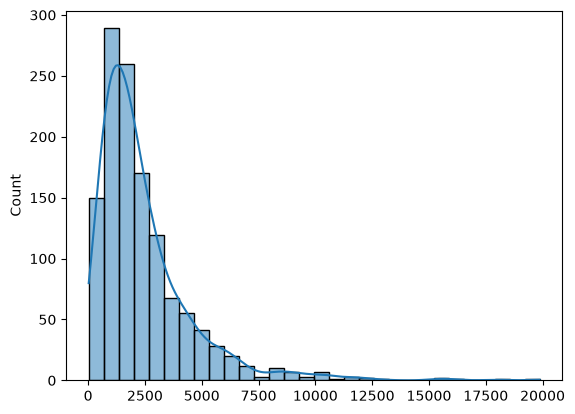

In [27]:
sns.histplot(distances_1,
             bins=30,
             kde=True)
plt.show()

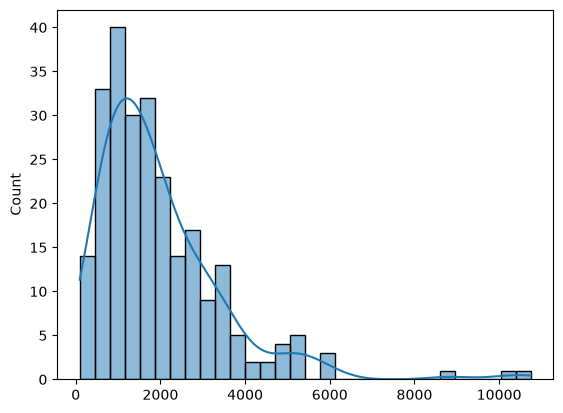

In [28]:
sns.histplot(distances_2,
             bins=30,
             kde=True)
plt.show()

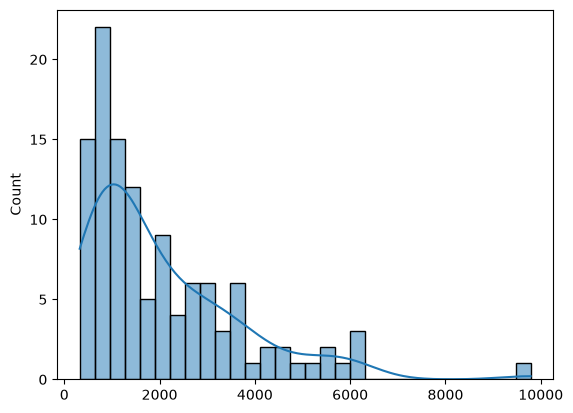

In [29]:
sns.histplot(distances_3,
             bins=30,
             kde=True)
plt.show()

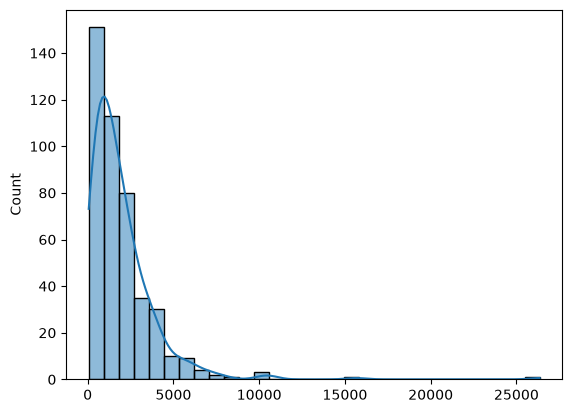

In [30]:
sns.histplot(distances_4,
             bins=30,
             kde=True)
plt.show()

take unexpressed data

In [31]:
df_all = pd.concat(
    [
        dist_mtx_unexpressed.assign(group="not expressed"),
        aggregated_mtx_1.assign(group="expressed, 1<=k<=5"),
        aggregated_mtx_4.assign(group="expressed, k>=16"),
    ],
    ignore_index=True,
)

fig, ax = plt.subplots(figsize=(6, 4))
sns.ecdfplot(data=df_all, x="dist", hue="group", log_scale=True, ax=ax)
ax.set_xlabel("Distance to 3′ end (transcript bp)")
plt.tight_layout()

NameError: name 'dist_mtx_unexpressed' is not defined

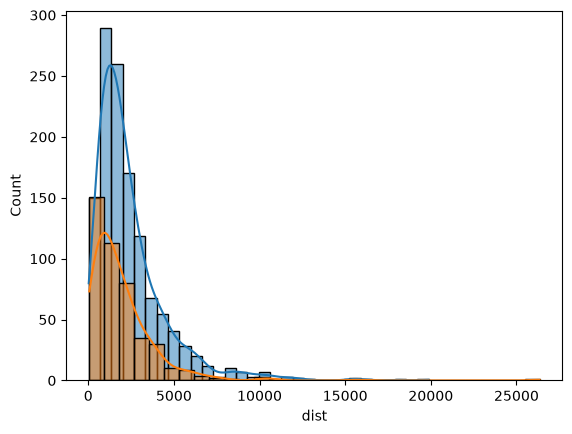

In [ ]:
#sns.histplot(dist_mtx_unexpressed["dist"], bins=30, kde=True)
sns.histplot(aggregated_mtx_1["dist"], bins=30, kde=True)
sns.histplot(aggregated_mtx_4["dist"], bins=30, kde=True)

plt.show()